In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('default')
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False 
import pickle
import os
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import StandardScaler
import matplotlib.ticker as ticker
cm = 1/2.54
# 字号
fontsize = 8

In [22]:
with open(r'C:\Users\Administrator\Desktop\long\3\code\data\HI.pkl', 'rb') as file:
    df = pickle.load(file)
# 删除含有NAN的行
HI = df.dropna()

In [23]:
HI.columns

Index(['CC_Var', 'CC_Ske', 'CC_Max', 'CC_Min', 'CC_Mean', 'CC_Kur', 'CV_Var',
       'CV_Ske', 'CV_Max', 'CV_Min', 'CV_Mean', 'CV_Kur', 'RE_Var', 'RE_Ske',
       'RE_Max', 'RE_Min', 'RE_Mean', 'RE_Kur', 'cycle', 'capacity', 'id'],
      dtype='object')

In [24]:
# 1. 定义指定的行排列顺序 (A有3个，B有6个)
A = ['CC', 'CV', 'RE']
B = ['Kur', 'Max', 'Mean', 'Min', 'Ske', 'Var']
desired_order = [f"{a}_{b}" for a in A for b in B]

# 将 capacity 放在最前面（对应您截图中的第一行）
final_order = ['capacity'] + desired_order

# 2. 计算相关系数绝对值（去掉 sort_values，保持原生状态）
cor = HI.drop(columns=['cycle', 'id']).corr()['capacity'].abs()
cor_s = HI.drop(columns=['cycle', 'id']).corr(method='spearman')['capacity'].abs()

# 3. 核心步骤：使用 reindex 按指定的列表顺序重新排列 Series 的行
cor = cor.reindex(final_order)
cor_s = cor_s.reindex(final_order)

# 4. 确保保存目录存在，避免路径报错
save_dir = r'C:\Users\Administrator\Desktop\long\3\code\3-HI'
os.makedirs(save_dir, exist_ok=True)

# 5. 保存为 CSV，使用 utf-8-sig 编码防止中文乱码
cor.to_csv(os.path.join(save_dir, '皮尔逊相关系数.csv'), encoding='utf-8-sig')
cor_s.to_csv(os.path.join(save_dir, '斯皮尔曼相关系数.csv'), encoding='utf-8-sig')

print("相关系数计算并按指定顺序重新排列完成，已保存至目标文件夹。")

相关系数计算并按指定顺序重新排列完成，已保存至目标文件夹。


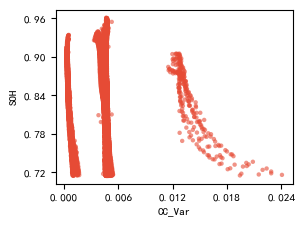

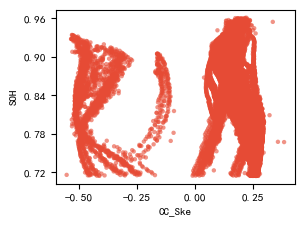

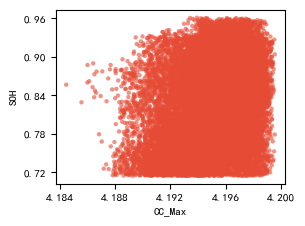

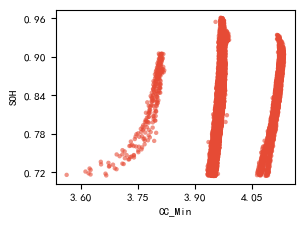

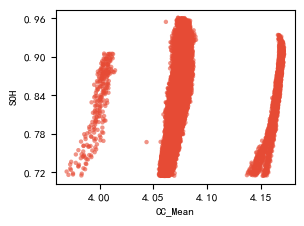

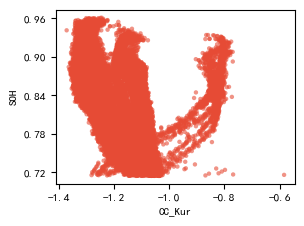

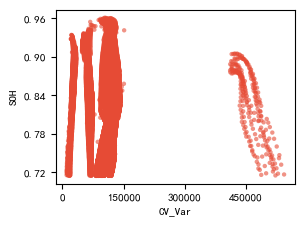

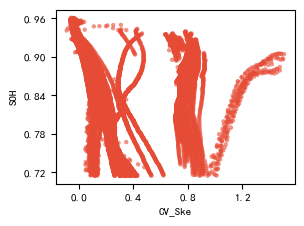

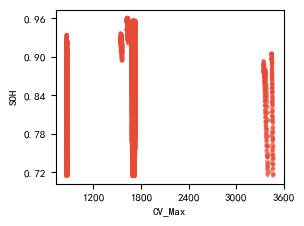

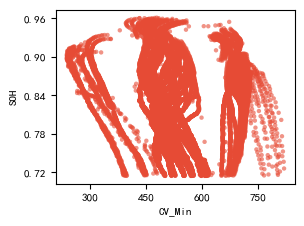

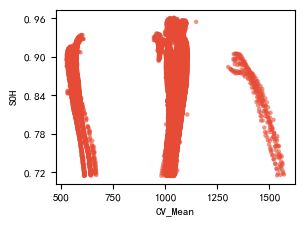

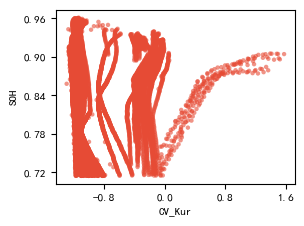

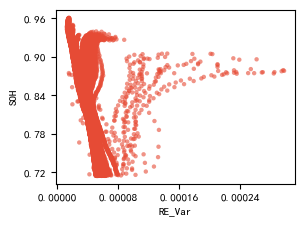

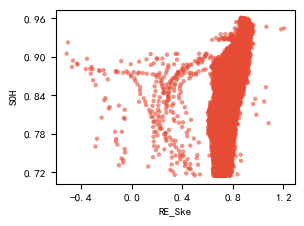

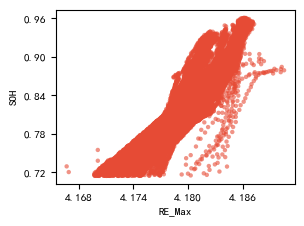

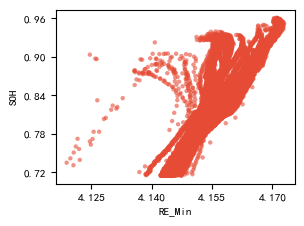

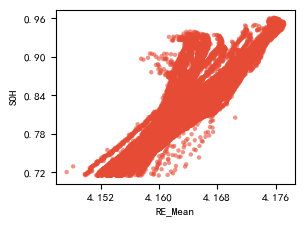

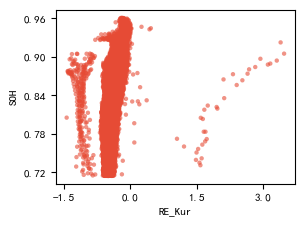

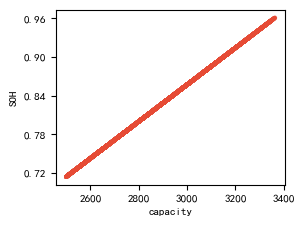

In [15]:
# 确保保存路径的文件夹存在，避免报错
save_dir = r'C:\Users\Administrator\Desktop\long\3\code\3-HI'
os.makedirs(save_dir, exist_ok=True)

# 遍历每个特征绘制与 capacity 的散点图
for i in HI.drop(columns=['cycle', 'id']).columns:
    plt.figure(figsize=(8*cm, 6*cm))
    
    # 【美化 1：数据点标识】
    # s=10: 适当调大点号（原本是1，偏小）
    # alpha=0.6: 增加透明度，数据重叠的地方颜色会加深，可以展现密度
    # c='#1f77b4': 使用 Matplotlib 经典的舒适蓝色
    # edgecolors='none': 去除点的轮廓线，使散点更柔和
    plt.scatter(HI[i], HI['capacity']/3500, s=10, alpha=0.6, c='#E64B35', edgecolors='none')
    plt.xlabel(i, fontsize=fontsize)
    plt.ylabel('SOH', fontsize=fontsize)
    
    # 【美化 2：限制 x 轴和 y 轴各有约 6 个刻度】
    # nbins=5 表示将其划分为 5 个区间，通常会产生 6 个刻度线
    # 使用 MaxNLocator 可以保证刻度值的数字是规整的（比如 0.2, 0.4 而不是 0.233, 0.466）
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    
    plt.xticks(fontsize=fontsize)
    plt.yticks(fontsize=fontsize)
    
    # 使用 tight_layout 优化边缘空白，配合 bbox_inches='tight' 效果更好
    plt.tight_layout()
    
    # 保存并显示
    plt.savefig(f'{save_dir}/{i}.png', dpi=600, bbox_inches='tight')
    plt.show()